# Task: Water Meter Data Visualization & EDA
#### in Phase 2 - Module 2: Data Visualization & EDA

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

1. Load Data

In [2]:
wwdata = pd.read_csv("..\\water_meter_readings.csv")
print("Successfully loaded water meter readings data")

Successfully loaded water meter readings data


2. Prepare Data

In [3]:
wwdata["DateTime"] = pd.to_datetime(wwdata["DateTime"])
wwdata = wwdata.sort_values("DateTime").reset_index(drop=True)
wwdata.head()

,DateTime,Meter_ID,Flow_Rate,Pressure,Temperature,Water_Volume
0,2024-01-01 00:00:00,METER_001,1.23,2.85,15.2,450
1,2024-01-01 01:00:00,METER_002,0.87,2.45,14.8,320
2,2024-01-01 02:00:00,METER_003,1.56,3.12,15.5,520
3,2024-01-01 03:00:00,METER_004,0.45,2.15,14.2,180
4,2024-01-01 04:00:00,METER_005,1.34,2.78,15.1,420


3. Identify outliers using statistical methods

In [4]:
numeric_data = wwdata[["Flow_Rate", "Pressure", "Water_Volume"]]

Q1 = numeric_data.quantile(0.25)
Q3 = numeric_data.quantile(0.75)

IQR = Q3 - Q1

outlier_check = ((numeric_data < (Q1 - 1.5 * IQR)) |
                 (numeric_data > (Q3 + 1.5 * IQR)))

outlier_values = numeric_data[outlier_check]
display(outlier_values.dropna(how="all"))

outliers = wwdata[outlier_check.any(axis=1)]

outliers

,Flow_Rate,Pressure,Water_Volume
30,4.67,1.25,NaN
35,5.12,0.95,NaN
40,4.89,1.05,NaN


,DateTime,Meter_ID,Flow_Rate,Pressure,Temperature,Water_Volume
30,2024-01-02 06:00:00,METER_001,4.67,1.25,16.8,950
35,2024-01-02 11:00:00,METER_001,5.12,0.95,17.2,1020
40,2024-01-02 16:00:00,METER_001,4.89,1.05,17.1,980


4. Consumption Trends Over Time

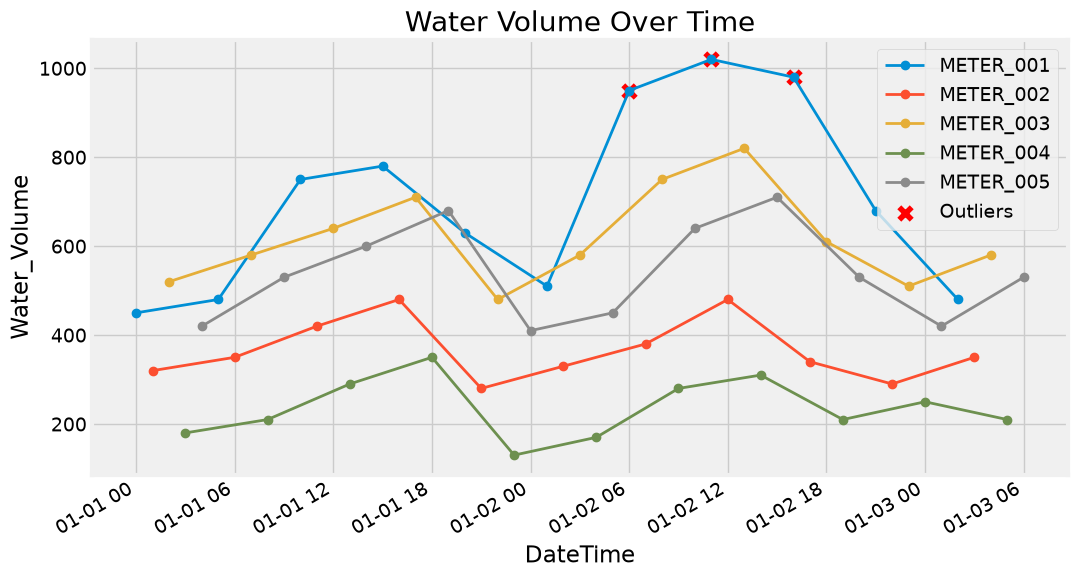

In [5]:
plt.figure(figsize=(11, 6))
plt.style.use("fivethirtyeight")
for meter_id, meter_data in wwdata.groupby("Meter_ID"):
    plt.plot(
        meter_data["DateTime"],
        meter_data["Water_Volume"],
        marker="o",
        linewidth=2,
        label=meter_id,
    )

plt.scatter(
    outliers["DateTime"],
    outliers["Water_Volume"],
    color="red",
    s=80,
    marker="x",
    label="Outliers",
)

plt.gcf().autofmt_xdate()
plt.title("Water Volume Over Time")
plt.xlabel("DateTime")
plt.ylabel("Water_Volume")
plt.legend()
plt.tight_layout()
plt.show()


5. Stack Plot: Water Volume by Meter Over Time

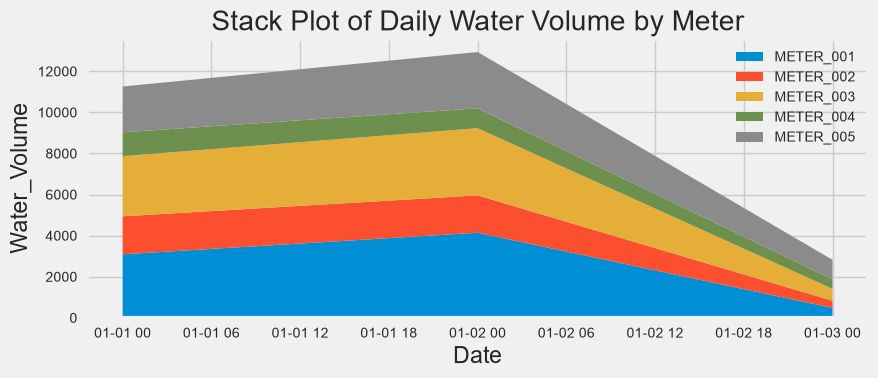

In [15]:
daily_data = wwdata.copy()
daily_data["Date"] = daily_data["DateTime"].dt.date

dates = sorted(daily_data["Date"].unique())
meters = sorted(daily_data["Meter_ID"].unique())

water_by_meter = []

for meter in meters:
    meter_daily = daily_data[daily_data["Meter_ID"] == meter].groupby("Date")["Water_Volume"].sum()
    water_by_meter.append([meter_daily.get(date, 0) for date in dates])

plt.figure(figsize=(9, 4))

plt.stackplot(dates, water_by_meter, labels=meters)
plt.title("Stack Plot of Daily Water Volume by Meter")
plt.xlabel("Date")
plt.ylabel("Water_Volume")
plt.legend()
plt.tight_layout()
plt.show()


6. Meter Share of Total Water Volume

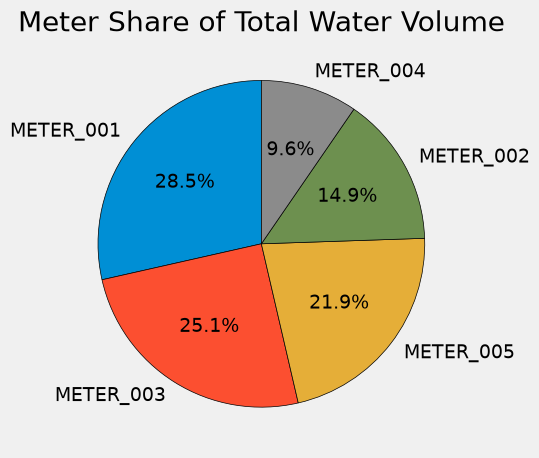

In [7]:
total_volume = wwdata.groupby("Meter_ID")["Water_Volume"].sum().sort_values(ascending=False)

plt.pie(total_volume.values, labels=total_volume.index, wedgeprops={'edgecolor':'black'}, autopct="%1.1f%%", startangle=90)
plt.title("Meter Share of Total Water Volume")
plt.tight_layout()
plt.show()

7. Meter Comparison: Average Flow Rate

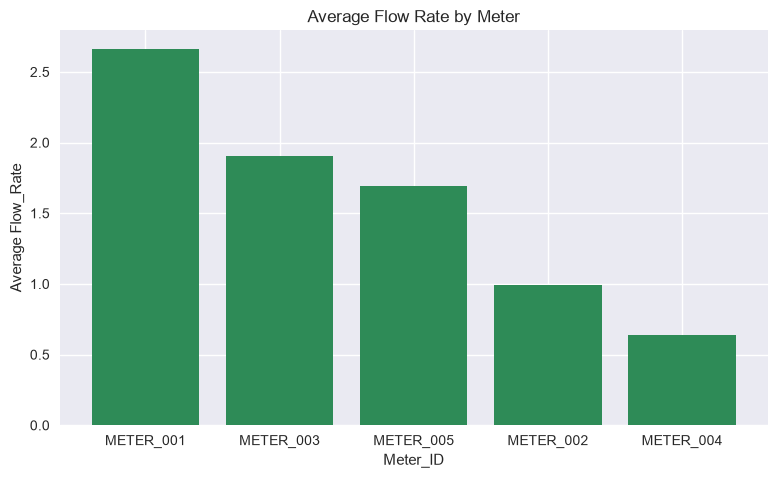

In [8]:
avg_flow = wwdata.groupby("Meter_ID")["Flow_Rate"].mean().sort_values(ascending=False)

plt.style.use('seaborn-v0_8')
plt.figure(figsize=(8, 5))
plt.bar(avg_flow.index, avg_flow.values, color="seagreen")
plt.title("Average Flow Rate by Meter")
plt.xlabel("Meter_ID")
plt.ylabel("Average Flow_Rate")
plt.tight_layout()
plt.show()

8. Meter Comparison: Average Pressure

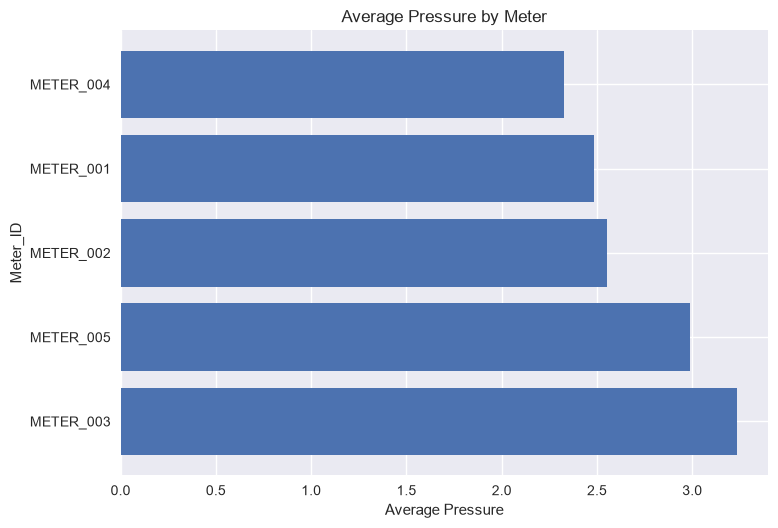

In [9]:
avg_pressure = wwdata.groupby("Meter_ID")["Pressure"].mean().sort_values(ascending=False)

plt.barh(avg_pressure.index, avg_pressure.values)
plt.title("Average Pressure by Meter")
plt.xlabel("Average Pressure")
plt.ylabel("Meter_ID")
plt.tight_layout()
plt.show()

9. Distribution of Water Volume

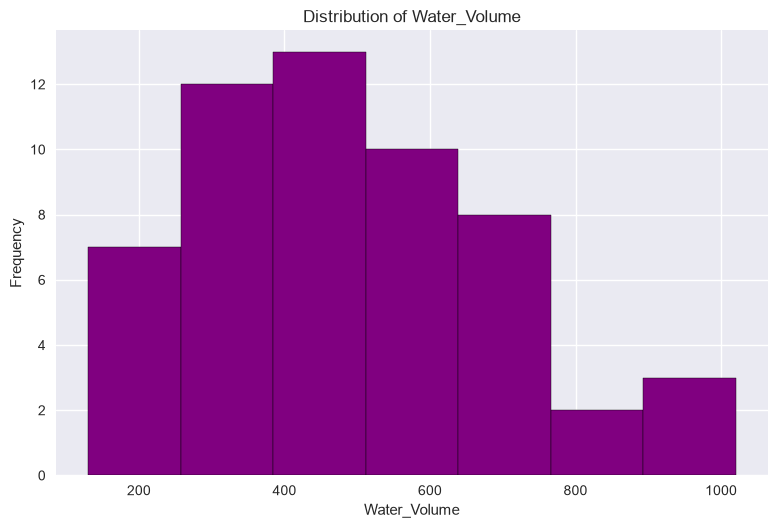

In [10]:
import math

# Choose the number of bins using the square root rule
# or can use "auto" for automatic bin selection : bins="auto"
bins_count = round(math.sqrt(len(wwdata)))

plt.hist(wwdata["Water_Volume"], bins=bins_count, color="purple", edgecolor="black")
plt.title("Distribution of Water_Volume")
plt.xlabel("Water_Volume")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

10. Box Plot by Meter

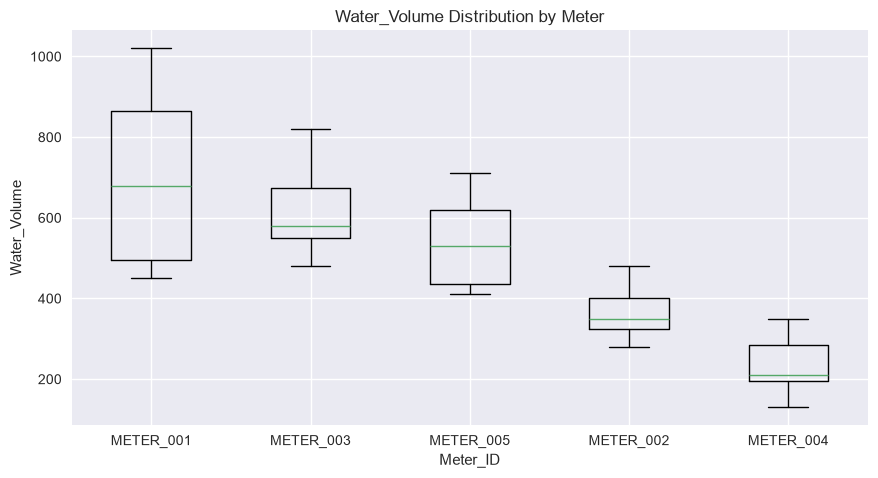

In [11]:
meter_order = wwdata.groupby("Meter_ID")["Water_Volume"].sum().sort_values(ascending=False).index
box_data = [wwdata.loc[wwdata["Meter_ID"] == meter_id, "Water_Volume"] for meter_id in meter_order]

plt.figure(figsize=(9, 5))
plt.boxplot(box_data, tick_labels=meter_order)
plt.title("Water_Volume Distribution by Meter")
plt.xlabel("Meter_ID")
plt.ylabel("Water_Volume")
plt.tight_layout()
plt.show()

11. Scatter Plot for Anomalies

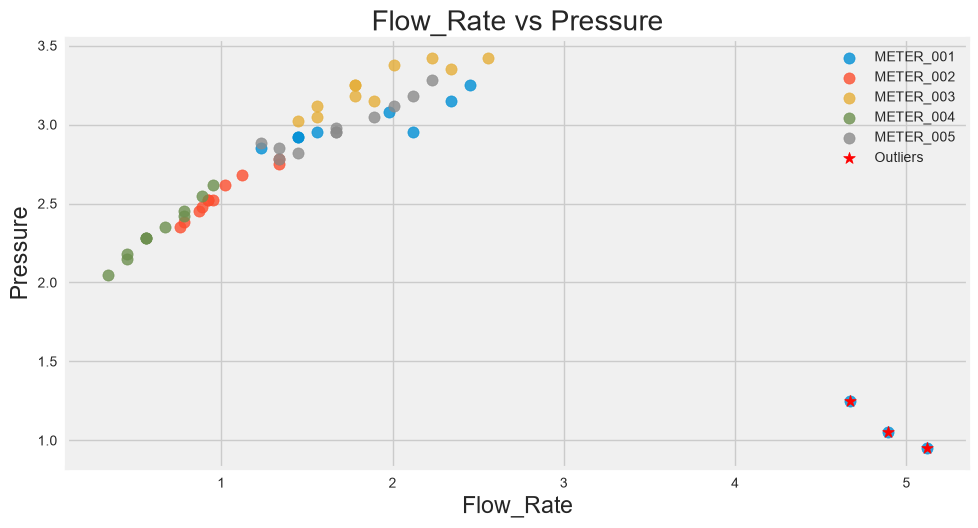

In [12]:
plt.figure(figsize=(10, 5.5))
plt.style.use('fivethirtyeight')

for meter_id, meter_data in wwdata.groupby("Meter_ID"):
    plt.scatter(
        meter_data["Flow_Rate"],
        meter_data["Pressure"],
        s=65,
        label=meter_id,
        alpha=0.8,
    )

plt.scatter(
    outliers["Flow_Rate"],
    outliers["Pressure"],
    color="red",
    s=77,
    marker="*",
    label="Outliers",
)

plt.title("Flow_Rate vs Pressure")
plt.xlabel("Flow_Rate")
plt.ylabel("Pressure")
plt.legend()
plt.tight_layout()

plt.savefig("last_plot.png", dpi=600)
plt.show()